# 07 - Text Model Interpretability

Goal: understand which words the text model uses to choose a category.

A linear SVM gives each word one weight per category. A high positive weight means the word pushes a product toward that category. We read these weights directly from the trained model.

1. Top words for each category.
2. Why the book categories get confused.
3. One wrong prediction explained word by word.

## 1. Train the optimised text model

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

from src.categories import CATEGORY_NAMES

data = pd.read_csv("../data/processed/text_train_processed.csv")
train = data[data["split"] == "train"]
validation = data[data["split"] == "validation"]

# Settings chosen in notebook 04
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, binary=True)
X_train = vectorizer.fit_transform(train["text_combined"])
X_validation = vectorizer.transform(validation["text_combined"])

model = LinearSVC(C=1, random_state=42).fit(X_train, train["prdtypecode"])

words = vectorizer.get_feature_names_out()
classes = list(model.classes_)
weights = model.coef_  # one row per category, one column per word

print(f"Words and word pairs: {len(words)}")
print(f"Categories: {len(classes)}")

Words and word pairs: 460326
Categories: 27


## 2. Top words for each category

For each category, the 8 words with the highest weight.

In [2]:
top_rows = []
for i, code_ in enumerate(classes):
    top = np.argsort(weights[i])[::-1][:8]
    top_rows.append({
        "Code": code_,
        "Category": CATEGORY_NAMES[code_],
        "Top words": ", ".join(words[top]),
    })

pd.DataFrame(top_rows).style.hide(axis="index")

Code,Category,Top words
10,Used Books,"edition de, and, in, der, die, cookbook, dico, und"
40,Games,"magideal, import, ensemble complet, la description, pal, simulator, essentials, quickio"
50,Game Accessories,"gaming, ps4, pour nintendo, manette, pour, skylanders, joystick, amiibo"
60,Consoles,"console, nom de, sony playstation, nom, pack xbox, 500 go, console de, bundle"
1140,Figurines,"figurine, shirt, magnet, figurines, gundam, mug, buste, watermelon"
1160,Cards,"carte, mtg, vf, vo, commune, pokemon, rare, attax"
1180,Wargames,"heroclix, warhammer, oop, miniatures, 40k, shadowrun, wargame, elfe"
1280,Toys,"peluche, puzzle, hélicoptère, poupée, doudou, playmobil, lego, kinder"
1281,Board Games,"propos, jeu, monopoly, tarot, cards, trivial, asmodee, cartes"
1300,RC Models,"générique, drone, maquette, 43, ho, dji, altaya, matchbox"


### Analysis

- Most categories have clear, sensible words: *piscine* and *intex* for Pool, *chien* and *laisse* for Pets, *warhammer* and *heroclix* for Wargames, *bébé* and *poussette* for Baby.
- Some top words are brand or seller names (*sweetheart93*, *germenly*, *lujuik*, *cdaffaires*). The model learned the sellers, not only the products. This works on this data but may not hold for new sellers.
- Some categories rely on the style of the text, not the product: New Books uses *ce livre*, *cet ouvrage*, *auteur* (words from a book summary), and Used Books uses English and German words (*and*, *der*, *die*) because many used books have foreign titles.

## 3. Why the book categories get confused

The four book categories, side by side. Each bar is the weight of one word for that category.

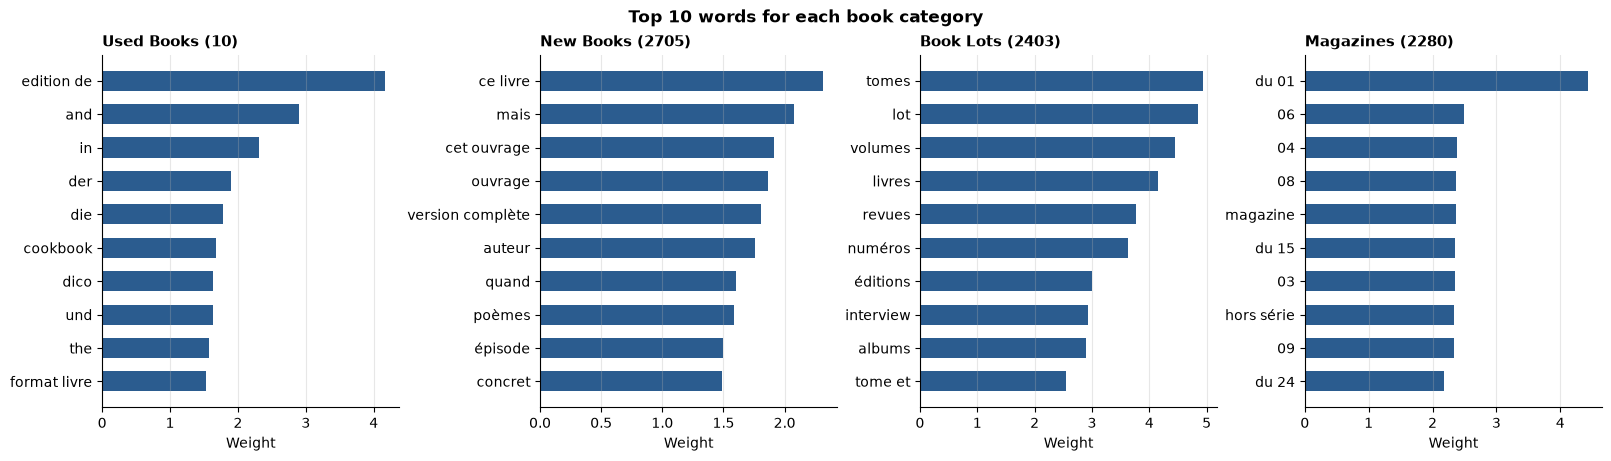

,Used Books,New Books,Book Lots,Magazines
Word,,,,
livre,0.04,0.16,1.97,-1.43
tome,0.77,0.51,1.34,-1.10
edition,0.03,-0.99,0.19,-0.55
édition,0.70,-0.50,0.79,-1.16
roman,0.24,0.49,0.58,0.44
auteur,-0.18,1.75,-0.45,-0.64
collection,0.30,-1.20,1.00,-0.48


In [3]:
book_codes = [10, 2705, 2403, 2280]

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5), constrained_layout=True)
for ax, code_ in zip(axes, book_codes):
    row = weights[classes.index(code_)]
    top = np.argsort(row)[::-1][:10]
    ax.barh(words[top][::-1], row[top][::-1], color="#2b5c8f", height=0.6)
    ax.set_title(f"{CATEGORY_NAMES[code_]} ({code_})", loc="left", fontsize=11, fontweight="bold")
    ax.set_xlabel("Weight")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", alpha=0.3)
fig.suptitle("Top 10 words for each book category", fontsize=12, fontweight="bold")
plt.show()

# Weight of common book words in each book category
common_words = ["livre", "tome", "edition", "édition", "roman", "auteur", "collection"]
word_index = {w: i for i, w in enumerate(words)}
common = pd.DataFrame(
    {CATEGORY_NAMES[c]: [weights[classes.index(c)][word_index[w]] for w in common_words if w in word_index] for c in book_codes},
    index=[w for w in common_words if w in word_index],
)
common.index.name = "Word"
common.style.format(precision=2)

### Analysis

- Each book category has its own strong words: *tomes*, *lot*, *volumes* for Book Lots, dates like *du 01* for Magazines, summary words for New Books, foreign words for Used Books.
- The common book words are weak and split across categories. *Roman* has almost the same weight (0.24 to 0.58) in all four. *Tome* and *édition* point to both Used Books and Book Lots.
- So a book title without one of the strong words (no "lot", no date, no summary) gives the model almost nothing to decide with. This is why book categories make 7 of the top 10 confused pairs.

## 4. One wrong prediction explained

We take a used book (10) that the model predicted as a book lot (2403). For each word in the product, its contribution to a category is its TF-IDF value times its weight. We compare the words that pushed toward the wrong category and toward the true one.

Title: la promenade au parc


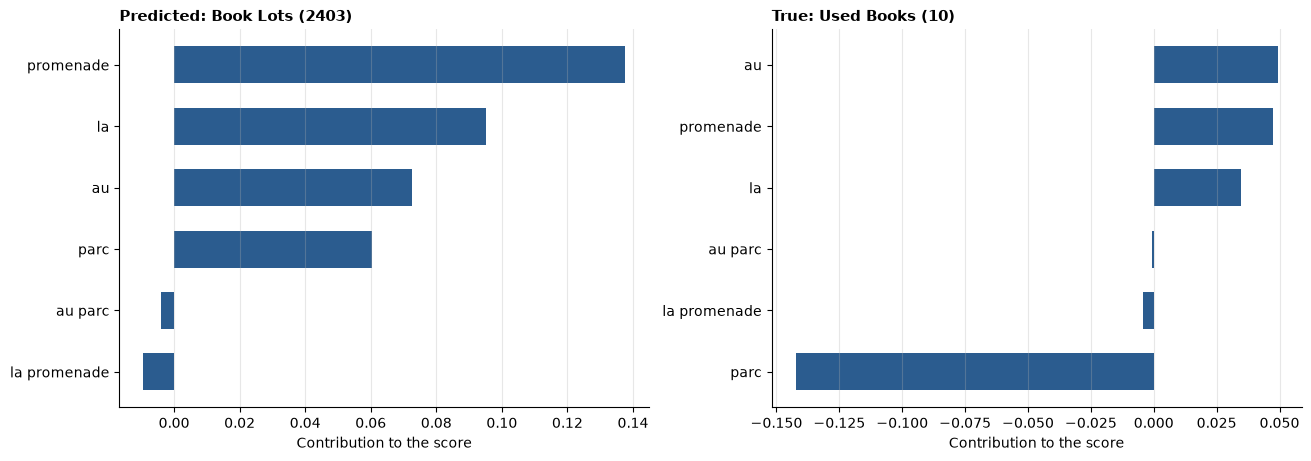

Score for Book Lots (2403): -0.50
Score for Used Books (10):  -0.68


In [4]:
predictions = model.predict(X_validation)
wrong = np.where((validation["prdtypecode"].to_numpy() == 10) & (predictions == 2403))[0]
idx = wrong[0]

x = X_validation[idx]
present = x.indices
print("Title:", validation["designation_clean"].iloc[idx])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
for ax, code_, label in [(axes[0], 2403, "Predicted"), (axes[1], 10, "True")]:
    contrib = x.data * weights[classes.index(code_)][present]
    order = np.argsort(contrib)[::-1][:8]
    ax.barh(words[present][order][::-1], contrib[order][::-1], color="#2b5c8f", height=0.6)
    ax.set_title(f"{label}: {CATEGORY_NAMES[code_]} ({code_})", loc="left", fontsize=11, fontweight="bold")
    ax.set_xlabel("Contribution to the score")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", alpha=0.3)
plt.show()

scores = model.decision_function(x)[0]
print(f"Score for Book Lots (2403): {scores[classes.index(2403)]:.2f}")
print(f"Score for Used Books (10):  {scores[classes.index(10)]:.2f}")

### Analysis

- The product is a used book with only a short title: *la promenade au parc*. It has no description.
- No word in it is a book word. The model only sees *promenade*, *la*, *au* and *parc*.
- Both scores are negative (-0.50 for Book Lots, -0.68 for Used Books), so the model is not confident in any category. Book Lots wins by a small margin, mainly because of *promenade*. *Parc* pushes away from Used Books.
- This shows a limit of text models: when the text is short and generic, there is not enough information. The image can help in these cases (see notebook 06).

## Conclusion

- The text model relies on clear, specific words, which explains its good overall score.
- It also learned seller names and writing style, which may not hold for new sellers.
- Book categories share weak, common words. Short book titles without a strong word are the main source of errors.